## 4 · Feature engineering

### By:
Sofía Arango Patiño

### Date:
2026-11-01

### Description:

Fourth step of the proof of concept ([issue #4](https://github.com/modsiw-mona/anomaly_detection_ato/issues/4);
CRISP-DM phase 3, *data preparation*; thesis objective **OE2**: build behaviour and anomaly features from the
authentication records).

1. **Cleaning** decisions — duplicates, outliers, missing values, population.
2. **Behavioural features**, one row per successful login, computed only from the past
   (`src/data/features.py` → `data/04_feature/`).
3. **No-future guarantee** — how it is tested, and a cross-check against the EDA.
4. **Development / test split** by the pre-registered rule (`src/data/split.py` → `data/05_model_input/`).
5. **Feature analysis on the development side only** — separation and redundancy.
6. **scikit-learn preprocessing pipeline** (`src/model/preprocessing.py`) — scaling, encoding, imputation, fitted
   on training data only.

From here on the **test side is not looked at** (beyond its size) until issue #7.

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

# Make the project's `src/` importable, wherever the notebook is opened from.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import logging
import resource
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from data.datasets import load_dataset_config
from data.features import DEFAULT_GROUPS, FEATURE_GROUPS, feature_columns, write_features
from data.split import load_side, split_path, write_split
from model.preprocessing import build_preprocessor, to_model_frame

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)
pl.Config.set_tbl_rows(45)
pl.Config.set_fmt_str_lengths(70)
pl.Config.set_tbl_width_chars(160)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE = "#2a78d6"  # categorical slot 1 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip

## 🧹 Cleaning decisions

Every decision below comes from a measurement in notebooks 2 or 3.

| Topic | Finding | Decision |
| --- | --- | --- |
| **Duplicates** | 0 identical rows, 0 repeated (user, millisecond) | Nothing to remove |
| **Population** | The model scores a login, and takeover labels sit on successful logins (140 of 141) | One row per **successful login** |
| **Catch-all user ID** | 14 M attempts, 227 countries — not a person | Removed from the population and from every history (`catch_all_user_ids`) |
| **Label window** | No takeover labelled after November 2020 | Rows only from Feb – Nov 2020 (`label_window`, decided by the thesis author); later months stay as history |
| **Outliers — counts** | Attempts per user are extremely heavy-tailed (median 2, max 1,927 successes) | Kept — real behaviour — and `log1p` in the preprocessing pipeline |
| **Outliers — RTT** | Present for 7% of logins and one takeover; up to 223 s | RTT group off by default; kept for its ablation |
| **Bots** | 2 M attempts, success rate 0.003% | Kept: they barely reach the population of successful logins |
| **Missing values** | Region / city null markers unified (#2); novelty undefined on a first login | Nulls kept in the feature table; imputed **inside** the pipeline, fitted on training folds only |
| **Artefacts** | Placeholder IP / ASN correlate with the label (EDA, ×2) | Kept as flags, **off by default**, for the ablation of issue #6 |

## 👷 Behavioural features

Feature groups, each motivated by the EDA (`FEATURE_GROUPS` in `src/data/features.py`):

In [3]:
MEANING = {
    "history": "Earlier successful logins of the user, whether this is the first, hours since the last one",
    "user_novelty": "First time THIS user succeeds with this country / ASN / IP / device / OS / browser / UA / region / city; how many key signals are new at once",
    "global_rarity": "Share of all earlier successful logins (all users) with this value — available even on a first login",
    "sharing": "Distinct accounts that succeeded from this IP / ASN before",
    "failures": "Failed attempts on the same account in the previous hour / day",
    "attack_ip": "IP found in known-attacker lists",
    "missingness": "Region / city missing",
    "device": "Device type (mobile, desktop, tablet, bot, unknown, missing)",
    "time": "Hour of day and weekday",
    "artefacts": "Synthesis placeholders (IP in 10.0.0.0/8, ASN >= 500000) — ablation only",
    "rtt": "Round-trip time and whether it is missing — ablation only",
}
pl.DataFrame(
    {
        "group": list(FEATURE_GROUPS),
        "default": ["yes" if g in DEFAULT_GROUPS else "ablation only" for g in FEATURE_GROUPS],
        "features": [len(cols) for cols in FEATURE_GROUPS.values()],
        "what it captures": [MEANING[g] for g in FEATURE_GROUPS],
    }
)

group,default,features,what it captures
str,str,i64,str
"""history""","""yes""",3,"""Earlier successful logins of the user, whether this is the first, hour…"
"""user_novelty""","""yes""",10,"""First time THIS user succeeds with this country / ASN / IP / device / …"
"""global_rarity""","""yes""",7,"""Share of all earlier successful logins (all users) with this value — a…"
"""sharing""","""yes""",2,"""Distinct accounts that succeeded from this IP / ASN before"""
"""failures""","""yes""",2,"""Failed attempts on the same account in the previous hour / day"""
"""attack_ip""","""yes""",1,"""IP found in known-attacker lists"""
"""missingness""","""yes""",2,"""Region / city missing"""
"""device""","""yes""",1,"""Device type (mobile, desktop, tablet, bot, unknown, missing)"""
"""time""","""yes""",2,"""Hour of day and weekday"""


Build the feature table from the intermediate dataset — streaming, over the whole timeline, then restricted to
the label window:

In [4]:
config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
start = time.perf_counter()
features_file = write_features(config, data_dir)
print(
    f"built {features_file.relative_to(REPO_ROOT)} in {time.perf_counter() - start:.0f} s, "
    f"{features_file.stat().st_size / 1e6:,.0f} MB"
)
features = pl.scan_parquet(features_file)
summary = features.select(
    pl.len().alias("logins"),
    pl.col("label_ato").sum().alias("takeovers"),
    pl.col("user_id").n_unique().alias("users"),
    pl.col("timestamp").min().alias("first"),
    pl.col("timestamp").max().alias("last"),
).collect()
summary

INFO Wrote rba_features.parquet


built data/04_feature/rba_features.parquet in 27 s, 708 MB


logins,takeovers,users,first,last
u32,u32,u32,datetime[ms],datetime[ms]
9840064,140,2768779,2020-02-03 12:43:55.873,2020-11-30 23:59:50.043


### Feature dictionary

In [5]:
schema = features.collect_schema()
nulls = features.select(pl.all().null_count()).collect().row(0, named=True)
rows = summary["logins"].item()
pl.DataFrame(
    [
        {
            "group": group,
            "feature": column,
            "dtype": str(schema[column]),
            "missing %": round(100 * nulls[column] / rows, 1),
        }
        for group, columns in FEATURE_GROUPS.items()
        for column in columns
    ]
)

group,feature,dtype,missing %
str,str,str,f64
"""history""","""prior_successes""","""UInt32""",0.0
"""history""","""first_success""","""Boolean""",0.0
"""history""","""hours_since_prev_success""","""Float64""",28.1
"""user_novelty""","""new_country""","""Boolean""",28.1
"""user_novelty""","""new_asn""","""Boolean""",28.1
"""user_novelty""","""new_ip""","""Boolean""",28.1
"""user_novelty""","""new_device_type""","""Boolean""",28.1
"""user_novelty""","""new_os""","""Boolean""",28.1
"""user_novelty""","""new_browser""","""Boolean""",28.1


Novelty and time-since-last are missing on **28%** of logins — exactly the share of first successful logins,
where they are undefined (`first_success` marks them). RTT is missing on 93%.

## 🔒 No information from the future

A feature of a login at time *t* may only use events before *t*. Two independent checks:

1. **Unit test** (`tests/data/test_features.py`): on random histories, every row's features are recomputed
   on the data **cut right after that row** and must be identical to the full computation. The test was
   itself checked by planting two leaks (global rarity counting future logins; "new country" judged against the
   user's whole history): both were caught.
2. **Cross-check against the EDA**: notebook 3 computed takeover novelty on a sample, with different, eager
   code. The feature table must reproduce it exactly:

In [6]:
takeovers = features.filter("label_ato").collect()
with_history = takeovers.filter(~pl.col("first_success"))
pl.DataFrame(
    {
        "measure": [
            "takeovers on a first success",
            "takeovers with history",
            "new country %",
            "new ASN %",
            "attack IP %",
        ],
        "EDA (notebook 3)": [54.0, 86.0, 80.2, 86.0, 54.7],
        "feature table": [
            float(takeovers["first_success"].sum()),
            float(with_history.height),
            round(100 * with_history["new_country"].mean(), 1),
            round(100 * with_history["new_asn"].mean(), 1),
            round(100 * with_history["attack_ip"].mean(), 1),
        ],
    }
).with_columns((pl.col("EDA (notebook 3)") == pl.col("feature table")).alias("match"))

measure,EDA (notebook 3),feature table,match
str,f64,f64,bool
"""takeovers on a first success""",54.0,54.0,true
"""takeovers with history""",86.0,86.0,true
"""new country %""",80.2,80.2,true
"""new ASN %""",86.0,86.0,true
"""attack IP %""",54.7,54.7,true


## ✂️ Development / test split

The rule fixed in the development plan was applied in the EDA: **random 20% of users, grouped by user,
stratified by label** (the last 20% of the timeline holds no takeover). Seeded, independent of row order:

In [7]:
write_split(config, data_dir)
split = pl.read_parquet(split_path(config, data_dir))
sides = []
for side in ("dev", "test"):
    sides.append(
        load_side(config, data_dir, side)
        .select(
            pl.lit(side).alias("side"),
            pl.col("user_id").n_unique().alias("users"),
            pl.len().alias("logins"),
            pl.col("label_ato").sum().alias("takeovers"),
        )
        .collect()
    )
pl.concat(sides).with_columns(
    pl.Series(
        "users with a takeover",
        [
            split.filter((pl.col("split") == s) & pl.col("has_takeover")).height
            for s in ("dev", "test")
        ],
    )
)

INFO Wrote rba_split.parquet


side,users,logins,takeovers,users with a takeover
str,u32,u32,u32,i64
"""dev""",2215023,7868084,112,110
"""test""",553756,1971980,28,28


No user appears on both sides (checked in `tests/data/test_split.py` and on this data). The test side gets 28
takeovers — enough for a final evaluation — and **is not opened again until issue #7**.

## 📊 Feature analysis — development side only

In [8]:
dev = load_side(config, data_dir, "dev").collect()
legit, takeover = dev.filter(~pl.col("label_ato")), dev.filter("label_ato")
peak_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS
print(
    f"dev: {dev.height:,} logins, {takeover.height} takeovers | peak memory so far: {peak_gb:.1f} GB"
)

dev: 7,868,084 logins, 112 takeovers | peak memory so far: 7.0 GB


### Separation of each feature

In [9]:
rows = []
for group in DEFAULT_GROUPS:
    for column in FEATURE_GROUPS[group]:
        if dev.schema[column] == pl.Boolean:
            a, b = legit[column].mean(), takeover[column].mean()
            rows.append(
                {
                    "group": group,
                    "feature": column,
                    "statistic": "% true",
                    "legitimate": round(100 * a, 2),
                    "takeover": round(100 * b, 2),
                    "takeover / legitimate": round(b / a, 1) if a else None,
                }
            )
        elif dev.schema[column].is_numeric():
            a, b = legit[column].median(), takeover[column].median()
            rows.append(
                {
                    "group": group,
                    "feature": column,
                    "statistic": "median",
                    "legitimate": round(a, 4) if a is not None else None,
                    "takeover": round(b, 4) if b is not None else None,
                    "takeover / legitimate": round(b / a, 2) if a and b is not None else None,
                }
            )
separation = pl.DataFrame(rows)
separation

group,feature,statistic,legitimate,takeover,takeover / legitimate
str,str,str,f64,f64,f64
"""history""","""prior_successes""","""median""",2.0,1.0,0.5
"""history""","""first_success""","""% true""",28.15,36.61,1.3
"""history""","""hours_since_prev_success""","""median""",99.8033,261.6569,2.62
"""user_novelty""","""new_country""","""% true""",0.78,78.87,101.3
"""user_novelty""","""new_asn""","""% true""",10.76,84.51,7.9
"""user_novelty""","""new_ip""","""% true""",40.78,97.18,2.4
"""user_novelty""","""new_device_type""","""% true""",9.33,32.39,3.5
"""user_novelty""","""new_os""","""% true""",22.58,47.89,2.1
"""user_novelty""","""new_browser""","""% true""",38.17,76.06,2.0


### Risk grows with the number of new signals

Takeover rate on the development side by how many key signals (country, ASN, device type, OS, browser) are new
for the user at once — with first logins as their own bucket:

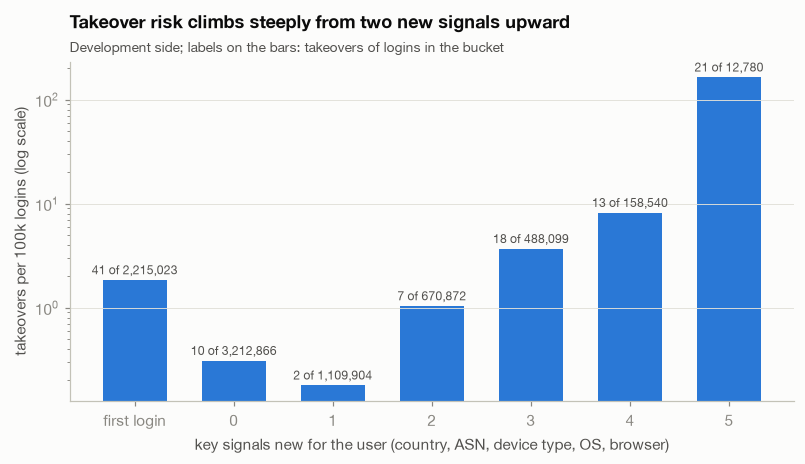

new key signals,logins,takeovers,per 100k logins
str,u32,u32,f64
"""first login""",2215023,41,1.85
"""0""",3212866,10,0.31
"""1""",1109904,2,0.18
"""2""",670872,7,1.04
"""3""",488099,18,3.69
"""4""",158540,13,8.2
"""5""",12780,21,164.32


In [10]:
buckets = (
    dev.with_columns(
        pl.when(pl.col("first_success"))
        .then(pl.lit("first login"))
        .otherwise(pl.col("n_new_key_signals").cast(pl.String))
        .alias("new key signals")
    )
    .group_by("new key signals")
    .agg(pl.len().alias("logins"), pl.col("label_ato").sum().alias("takeovers"))
    .with_columns((1e5 * pl.col("takeovers") / pl.col("logins")).round(2).alias("per 100k logins"))
    .sort(pl.col("new key signals").replace({"first login": "-1"}).cast(pl.Int8))
)
fig, ax = plt.subplots(figsize=(8.5, 4))
bars = ax.bar(buckets["new key signals"], buckets["per 100k logins"], color=BLUE, width=0.65)
ax.bar_label(
    bars,
    labels=[f"{t} of {n:,}" for t, n in zip(buckets["takeovers"], buckets["logins"], strict=True)],
    color=INK_2,
    fontsize=8,
    padding=2,
)
ax.set_yscale("log")
ax.grid(axis="y")
ax.set_xlabel("key signals new for the user (country, ASN, device type, OS, browser)")
ax.set_ylabel("takeovers per 100k logins (log scale)")
ax.set_title("Takeover risk climbs steeply from two new signals upward", pad=22)
ax.text(
    0,
    1.02,
    "Development side; labels on the bars: takeovers of logins in the bucket",
    transform=ax.transAxes,
    color=INK_2,
    fontsize=9,
    va="bottom",
)
plt.show()
buckets

### Redundancy between features

Pairs of default features that move together (Pearson correlation on a seeded 1 M-row sample of the development
side, nulls treated as their imputed value 0 / median):

In [11]:
MIN_CORRELATION = 0.7  # pairs at least this correlated are listed
columns = feature_columns()
sample = dev.sample(n=1_000_000, seed=20261101)
numeric = to_model_frame(sample, [c for c in columns if c != "device_type"])
numeric = numeric.with_columns(pl.all().fill_null(strategy="mean"))
corr = numeric.corr()
names = corr.columns
pairs = [
    {"feature A": names[i], "feature B": names[j], "correlation": round(corr[i, j], 3)}
    for i in range(len(names))
    for j in range(i + 1, len(names))
    if abs(corr[i, j]) >= MIN_CORRELATION
]
pl.DataFrame(pairs).sort(pl.col("correlation").abs(), descending=True)

feature A,feature B,correlation
str,str,f64
"""region_missing""","""city_missing""",0.985
"""new_region""","""new_city""",0.879
"""global_share_asn""","""asn_prior_users""",0.843
"""new_os""","""n_new_key_signals""",0.841
"""new_browser""","""new_user_agent""",0.836
"""new_browser""","""n_new_key_signals""",0.813
"""global_share_ip""","""ip_prior_users""",0.812
"""new_ip""","""new_city""",0.755
"""fails_1h""","""fails_24h""",0.744


Strongly correlated pairs are expected (a new IP often comes with a new region and city; a first login has a
missing "time since last"). Nothing is removed here: tree models are robust to redundancy, and **feature
selection is done with the ablations of issue #6**, where removing a group must not hurt validation results.

## ⚙️ scikit-learn preprocessing pipeline

`build_preprocessor()` returns an **unfitted** `ColumnTransformer`. Each family of features gets its own
treatment (imputation → transformation → scaling / encoding), so the statistics it learns come only from the
data it is fitted on. In issue #5 it is fitted inside each cross-validation fold. Here, as a demonstration, it
is fitted on the same 1 M-row development sample:

In [12]:
preprocessor = build_preprocessor(columns)
transformed = preprocessor.fit_transform(to_model_frame(sample, columns))
out_names = list(preprocessor.get_feature_names_out())
print(f"{len(columns)} input features -> {transformed.shape[1]} model columns")
pl.DataFrame(
    {
        "step": [name for name, _, _ in preprocessor.transformers_ if name != "remainder"],
        "input columns": [
            ", ".join(cols) for name, _, cols in preprocessor.transformers_ if name != "remainder"
        ],
    }
)

30 input features -> 37 model columns


step,input columns
str,str
"""device_type""","""device_type"""
"""hour""","""hour"""
"""weekday""","""weekday"""
"""counts""","""prior_successes, hours_since_prev_success, n_new_key_signals, ip_prior…"
"""shares""","""global_share_country, global_share_asn, global_share_ip, global_share_…"
"""booleans""","""first_success, new_country, new_asn, new_ip, new_device_type, new_os, …"


In [13]:
pl.DataFrame(
    {
        "model column": out_names,
        "mean": np.round(transformed.mean(axis=0), 2),
        "std": np.round(transformed.std(axis=0), 2),
        "missing": np.isnan(transformed).sum(axis=0),
    }
)

model column,mean,std,missing
str,f64,f64,i64
"""device_type_bot""",0.0,0.0,0
"""device_type_desktop""",0.34,0.47,0
"""device_type_missing""",0.0,0.0,0
"""device_type_mobile""",0.62,0.49,0
"""device_type_tablet""",0.04,0.19,0
"""device_type_unknown""",0.0,0.03,0
"""hour_sin""",-0.1,0.74,0
"""hour_cos""",-0.31,0.59,0
"""weekday_sin""",0.04,0.71,0


Scaled columns have mean 0 and standard deviation 1, booleans stay in {0, 1}, and there are no missing values.

## 📊 Analysis of Results and Conclusions

- **The feature table is built from the whole timeline but only ever looks back.** 9.84 M successful logins of
  real accounts in the label window, 140 takeovers, 38 columns, in under a minute on the laptop. The no-future
  guarantee is enforced by a unit test that was itself shown to catch planted leaks, and the takeover statistics
  reproduce the EDA exactly although the code is independent.
- **Cleaning is decided by evidence, not by default rules**: no duplicates to drop; the catch-all ID removed;
  heavy tails kept and log-transformed; RTT and placeholder artefacts kept but off by default, pending their
  ablations; nulls kept until the pipeline imputes them on training data.
- **The split follows the pre-registered rule**: 2.2 M development users (112 takeovers) and 554 k test users
  (28 takeovers), grouped by user and stratified. The test side stays closed until issue #7.
- **On the development side, the behavioural features separate takeovers clearly.** With zero or one new key
  signal the takeover rate is low (0.2 – 0.3 per 100k logins); from two upward it climbs steeply, reaching
  ~164 per 100k when all five are new — about 500 times the rate with none. This is the core idea of OE2, now
  as features.
- **First logins keep a signal**: global rarity, sharing and attack-IP features are defined on them, which is the
  only way to address the 39% of takeovers without history.
- **The preprocessing pipeline** imputes, transforms, scales and one-hot encodes every family of features, keeps
  its output shape stable even when a fold has no value for a column, and learns its statistics only from what it
  is fitted on.

## 💡 Proposals and Ideas

- **Issue #5 (baseline):** dummy model, the Freeman RBA score, and the single-signal rules (new country, attack IP),
  evaluated with repeated user-grouped stratified cross-validation on the development side: PR-AUC, recall at
  alert budgets, friction.
- **Issue #6:** the ablations prepared here — artefact flags, RTT, geography (region / city novelty), time
  features — decide feature selection.
- **Course part 2:** `write_features` + `write_split` are already the core of the feature pipeline script
  (`src/pipelines/feature_pipeline`); they only need wiring and data validation at the entry point.

## 📖 References

- Freeman, D., Jain, S., Dürmuth, M., Biggio, B., & Giacinto, G. (2016). Who Are You? A Statistical Approach to
  Measuring User Authenticity. *NDSS*. https://doi.org/10.14722/ndss.2016.23240
- Wiefling, S., Jørgensen, P. R., Thunem, S., & Lo Iacono, L. (2022). Pump Up Password Security! *ACM TOPS*,
  26(1). https://doi.org/10.1145/3546069
- scikit-learn: *Column Transformer with Mixed Types*; *Common pitfalls — data leakage*.
  https://scikit-learn.org/stable/common_pitfalls.html
- Course methodology — feature engineering: https://joserzapata.github.io/post/ciencia-datos-proyecto-python/4-feat_eng/